# Supernova neutrinos with SupernovaNeutrinos.jl

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuliaNeutrino/SupernovaNeutrinos.jl/blob/main/notebooks/01_supernova_neutrinos.ipynb)

A core-collapse supernova emits about 99% of its 3 × 10⁵³ erg as neutrinos of all flavors, in about ten seconds. On the way out, the neutrinos cross the star's MSW resonances, perhaps decohere or decay, and finally arrive at detectors on Earth. SupernovaNeutrinos.jl, a Julia port of [SNEWPY](https://github.com/SNEWS2/snewpy), covers the first two steps:

- **models**: the 24 simulations of the SNEWS model repositories, downloaded on demand, plus analytic pinched spectra;
- **flavor transformations** in the supernova, in vacuum, and their combinations.

[SNOwGLoBES.jl](https://github.com/JuliaNeutrino/SNOwGLoBES.jl) turns the resulting fluences into event rates in real detectors. This notebook goes through the package and shows how mass ordering and progenitor show up in DUNE, Hyper-Kamiokande and IceCube.

In [ ]:
# Install the packages from GitHub, plus Plots and the readers of the FITS and HDF5 model files (the first run takes a few minutes).
# On your own computer, skip this cell if they are already installed.
using Pkg
Pkg.add(url = "https://github.com/JuliaNeutrino/GLoBES.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/SNOwGLoBES.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/SupernovaNeutrinos.jl")
Pkg.add(["Plots", "FITSIO", "HDF5"])

In [1]:
using SupernovaNeutrinos, SNOwGLoBES, Plots
using FITSIO, HDF5   # load the readers of FITS and HDF5 model files

# One color per flavor, the same in every plot
const FLAVOR_COLOR = Dict(:e => "#2a78d6", :e_bar => "#eb6834", :mu => "#1baf7a", :mu_bar => "#eda100")
const LABEL = Dict(:e => "ν_e", :e_bar => "ν̄_e", :mu => "ν_x", :mu_bar => "ν̄_x")
default(linewidth = 2, framestyle = :axes, gridalpha = 0.15, legend = :topright, background_color = "#fcfcfb", foreground_color_legend = nothing)

## The models

Every model of the SNEWS repositories is a type. Its parameters (progenitor mass, equation of state, …) pick one simulation:

In [2]:
[(model = nameof(M), simulations = length(param_combinations(M))) for M in all_models()]

24-element Vector{@NamedTuple{model::Symbol, simulations::Int64}}:
 (model = :Bollig_2016, simulations = 2)
 (model = :Bugli_2021, simulations = 20)
 (model = :Fischer_2020, simulations = 1)
 (model = :Fornax_2019, simulations = 9)
 (model = :Fornax_2021, simulations = 15)
 (model = :Fornax_2022, simulations = 100)
 (model = :Fornax_2024, simulations = 24)
 (model = :Kuroda_2020, simulations = 3)
 (model = :Mori_2023, simulations = 14)
 (model = :Nakazato_2013, simulations = 24)
 (model = :OConnor_2013, simulations = 64)
 (model = :OConnor_2015, simulations = 1)
 (model = :Sukhbold_2015, simulations = 4)
 (model = :Takata_2025, simulations = 99)
 (model = :Tamborra_2014, simulations = 5)
 (model = :Walk_2018, simulations = 9)
 (model = :Walk_2019, simulations = 5)
 (model = :Warren_2020, simulations = 600)
 (model = :Zha_2021, simulations = 15)
 (model = :Kato_2017, simulations = 2)
 (model = :Myers_2026, simulations = 32)
 (model = :Odrzywolek_2010, simulations = 2)
 (model = :Patton_

In [3]:
parameters(Nakazato_2013)   # allowed values of each parameter

(progenitor_mass = Parameter(Any[13.0, 20.0, 30.0, 50.0], "", "", "M☉"), revival_time = Parameter(Any[0.0, 100.0, 200.0, 300.0], "", "", "ms"), metallicity = Parameter(Any[0.02, 0.004], "", "", ""), eos = Parameter(Any["LS220", "shen", "togashi"], "", "", ""))

A model is built from its parameters. The first time, its file is downloaded to a scratch space (set `SUPERNOVANEUTRINOS_MODELS` to use your own directory). This is the 27 M☉ simulation of Bollig et al. (2016):

In [4]:
model = Bollig_2016(progenitor_mass = 27)

Bollig_2016 model: s27.0c
  9850 time points, -0.344628 … 8.3502 s
  Progenitor mass   27
  EOS               LS220

## Containers

Every quantity, whether spectrum, flux, fluence or event rate, is a `Container`: a `(flavor, time, energy)` array that records its own units. Units are fixed: MeV, s, cm, kpc. `initial_spectra` gives the neutrinos emitted per MeV per second, before any flavor transformation:

In [5]:
t = times(model)
E = range(0, 100, length = 201)   # MeV
S = initial_spectra(model, t, E)
S.unit, size(S), S.flavor

(MeV⁻¹ s⁻¹, (6, 9850, 201), Flavor[ThreeFlavor.NU_E, ThreeFlavor.NU_E_BAR, ThreeFlavor.NU_MU, ThreeFlavor.NU_MU_BAR, ThreeFlavor.NU_TAU, ThreeFlavor.NU_TAU_BAR])

Flavors are selected with `S[:e]`, `S[:e_bar]`, `S[:mu]`, … and axes are integrated with `integrate` (the exact integral of the linear interpolation). Integrating the spectrum over energy gives the number of neutrinos emitted per second; integrating E × spectrum gives the luminosity:

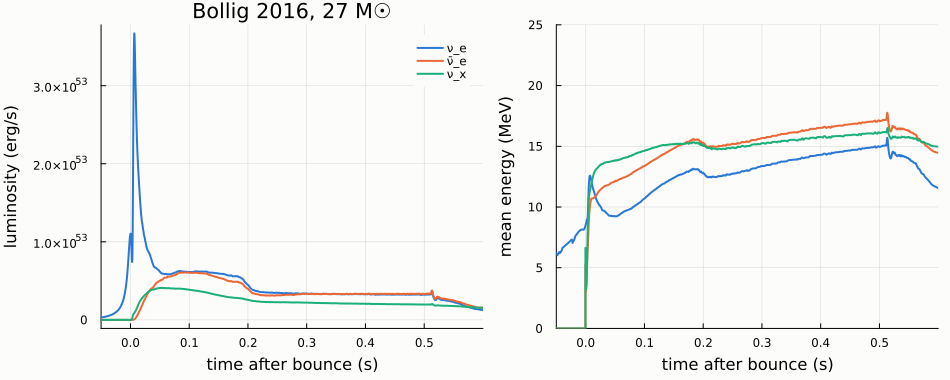

In [6]:
const MeV_TO_ERG = 1.602176634e-6
trapezoid(y, x) = sum((y[1:end-1] .+ y[2:end]) ./ 2 .* diff(x))
number(S, f) = [trapezoid(S[f].array[1, i, :], S.energy) for i in axes(S.array, 2)]                        # neutrinos per s
luminosity(S, f) = [trapezoid(S[f].array[1, i, :] .* S.energy, S.energy) for i in axes(S.array, 2)] .* MeV_TO_ERG   # erg per s
p1 = plot(; xlabel = "time after bounce (s)", ylabel = "luminosity (erg/s)", xlims = (-0.05, 0.6), title = "Bollig 2016, 27 M☉")
p2 = plot(; xlabel = "time after bounce (s)", ylabel = "mean energy (MeV)", xlims = (-0.05, 0.6), ylims = (0, 25), legend = false)
for f in (:e, :e_bar, :mu)
    plot!(p1, t, luminosity(S, f); label = LABEL[f], color = FLAVOR_COLOR[f])
    plot!(p2, t, luminosity(S, f) ./ MeV_TO_ERG ./ max.(number(S, f), 1e-300); color = FLAVOR_COLOR[f])
end
plot(p1, p2; layout = (1, 2), size = (950, 380), bottom_margin = 5Plots.mm, left_margin = 4Plots.mm)

The phases of the explosion are visible:

- At the bounce, the shock breaks out of the neutrinosphere and a ~10 ms **neutronization burst** of ν_e (from $e^- p \to n \nu_e$) reaches ~10⁵³ erg/s.
- **Accretion** follows, while matter falls onto the proto-neutron star.
- Then a slow **cooling** phase.

The hierarchy ⟨E_νe⟩ < ⟨E_ν̄e⟩ < ⟨E_νx⟩ follows from how deep each flavor decouples: ν_x only have neutral-current interactions.

## Flavor transformations

Inside the star, the neutrinos cross the MSW resonances of the H (Δm²31) and L (Δm²21) splittings. If the crossing is adiabatic, each flavor leaves as one mass state. `P_ff` gives the matrix of probabilities P(ν_α → ν_β) at Earth. With normal ordering, ν_e leave as ν_3, which has only |U_e3|² ≈ 2% of ν_e:

In [7]:
normal = TransformationChain(AdiabaticMSW(); mixing_params = MixingParameters(:normal))
inverted = TransformationChain(AdiabaticMSW(); mixing_params = MixingParameters(:inverted))
P_ff(normal, [0.1], [10.0])

FlavorMatrix(ThreeFlavorFlavorBasis ← ThreeFlavorFlavorBasis, size (6, 6, 1, 1))
                    NU_E        NU_MU       NU_TAU     NU_E_BAR    NU_MU_BAR   NU_TAU_BAR
NU_E             0.02215       0.4994       0.4784            0            0            0
NU_MU             0.4599       0.2612       0.2788            0            0            0
NU_TAU            0.5179       0.2394       0.2427            0            0            0
NU_E_BAR               0            0            0       0.6771       0.1692       0.1537
NU_MU_BAR              0            0            0        0.112       0.4431       0.4449
NU_TAU_BAR             0            0            0       0.2109       0.3877       0.4014

The survival probabilities P(ν_e → ν_e) and P(ν̄_e → ν̄_e) are the key numbers. They depend on the ordering and on the adiabaticity of the H resonance:

In [8]:
survival(x) = (P = P_ff(x, [0.1], [10.0]); (ν_e = round(P[:e, :e]; digits = 3), ν̄_e = round(P[:e_bar, :e_bar]; digits = 3)))
transformations = ["none" => NoTransformation(),
                   "adiabatic MSW, normal" => normal,
                   "adiabatic MSW, inverted" => inverted,
                   "non-adiabatic H, normal" => TransformationChain(NonAdiabaticMSWH(); mixing_params = MixingParameters(:normal)),
                   "complete exchange" => CompleteExchange(),
                   "3-flavor decoherence" => ThreeFlavorDecoherence()]
[(transformation = name, survival(x)...) for (name, x) in transformations]

6-element Vector{@NamedTuple{transformation::String, ν_e::Float64, ν̄_e::Float64}}:
 (transformation = "none", ν_e = 1.0, ν̄_e = 1.0)
 (transformation = "adiabatic MSW, normal", ν_e = 0.022, ν̄_e = 0.677)
 (transformation = "adiabatic MSW, inverted", ν_e = 0.301, ν̄_e = 0.022)
 (transformation = "non-adiabatic H, normal", ν_e = 0.301, ν̄_e = 0.677)
 (transformation = "complete exchange", ν_e = 0.0, ν̄_e = 0.0)
 (transformation = "3-flavor decoherence", ν_e = 0.333, ν̄_e = 0.333)

## Fluence at Earth

`flux` applies a transformation and the distance (default 10 kpc, about the Galactic center). `integrate` over time gives the fluence of the whole burst, in neutrinos per cm² per MeV:

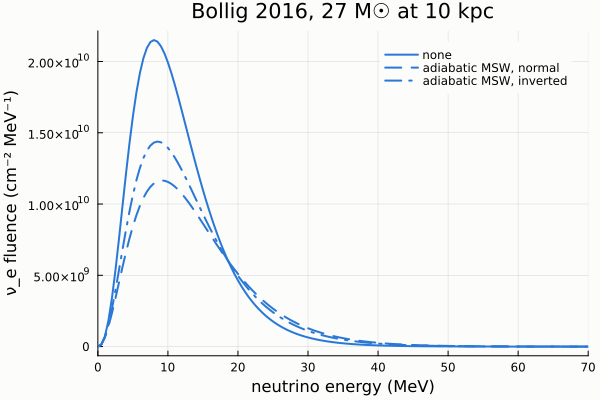

In [9]:
fluence(x) = integrate(flux(model, t, E; distance = 10, transformation = x), :time)
fluences = Dict(name => fluence(x) for (name, x) in transformations[1:3])
plt = plot(; xlabel = "neutrino energy (MeV)", ylabel = "ν_e fluence (cm⁻² MeV⁻¹)", xlims = (0, 70), title = "Bollig 2016, 27 M☉ at 10 kpc")
for (name, style) in (("none", :solid), ("adiabatic MSW, normal", :dash), ("adiabatic MSW, inverted", :dashdot))
    plot!(plt, E, vec(fluences[name][:e].array); label = name, linestyle = style, color = FLAVOR_COLOR[:e])
end
plt

The transformations swap the ν_e spectrum for the hotter ν_x spectrum, almost completely for normal ordering. The detected ν_e therefore get harder.

## Events in detectors

SNOwGLoBES.jl takes these fluences directly. Three detectors that see different flavors:

- DUNE: 40 kt of liquid argon, mostly ν_e through ν_e CC on ⁴⁰Ar.
- Hyper-Kamiokande: about 100 kt of water, mostly ν̄_e through inverse β decay.
- IceCube: counts the Cherenkov light of inverse β decays across the ice.

In [10]:
detectors = (DUNE = SupernovaDetector(:ar40kt, :argon), HyperK = SupernovaDetector(:wc100kt30prct, :water), IceCube = SupernovaDetector(:icecube, :water))
[(transformation = name, map(det -> round(Int, total_events(event_rates(det, fluences[name]))), detectors)...) for name in ("none", "adiabatic MSW, normal", "adiabatic MSW, inverted")]

3-element Vector{@NamedTuple{transformation::String, DUNE::Int64, HyperK::Int64, IceCube::Int64}}:
 (transformation = "none", DUNE = 4305, HyperK = 24290, IceCube = 652376)
 (transformation = "adiabatic MSW, normal", DUNE = 5512, HyperK = 24235, IceCube = 661491)
 (transformation = "adiabatic MSW, inverted", DUNE = 5178, HyperK = 23593, IceCube = 659379)

## The neutronization burst: a mass ordering signature

Integrating the flux over time bins instead of over the whole burst gives one fluence, and one set of rates, per bin. The ν_e CC rate in DUNE during the first 300 ms shows the neutronization peak. With normal ordering it is almost entirely converted away (P_ee ≈ 2%). With inverted ordering about 30% survives:

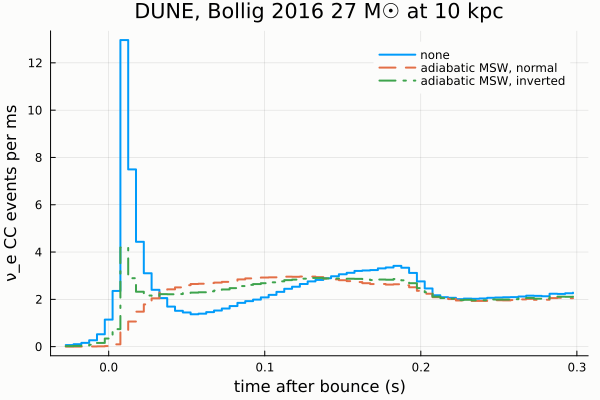

In [11]:
edges = range(-0.03, 0.3, step = 0.005)   # 5 ms bins
dune = SupernovaDetector(:ar40kt, :argon)
plt = plot(; xlabel = "time after bounce (s)", ylabel = "ν_e CC events per ms", title = "DUNE, Bollig 2016 27 M☉ at 10 kpc")
for (name, style) in (("none", :solid), ("adiabatic MSW, normal", :dash), ("adiabatic MSW, inverted", :dashdot))
    bins = integrate(flux(model, t, E; transformation = Dict(transformations)[name]), :time; limits = edges)
    rates = event_rates(dune, bins)
    plot!(plt, edges[1:end-1] .+ step(edges) / 2, [total_events(r["nue_Ar40"]) for r in rates] ./ (1000step(edges)); label = name, linestyle = style, seriestype = :steppost)
end
plt

## Comparing simulations

The SNEWS models come from many groups and codes. Some are stored as FITS (Nakazato) and some as HDF5 (Warren), which is why `FITSIO` and `HDF5` were loaded above. Here is the ν̄_e luminosity, the flavor that water and ice detectors see best, for four simulations:

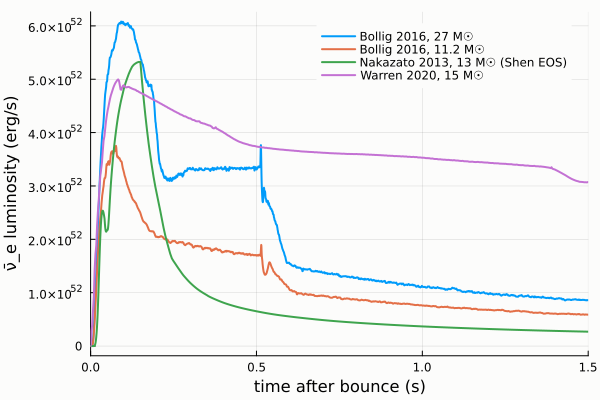

In [12]:
models = ["Bollig 2016, 27 M☉" => model,
          "Bollig 2016, 11.2 M☉" => Bollig_2016(progenitor_mass = 11.2),
          "Nakazato 2013, 13 M☉ (Shen EOS)" => Nakazato_2013(progenitor_mass = 13, revival_time = 100, metallicity = 0.02, eos = "shen"),
          "Warren 2020, 15 M☉" => Warren_2020(progenitor_mass = 15, turbmixing_param = 1.25)]
plt = plot(; xlabel = "time after bounce (s)", ylabel = "ν̄_e luminosity (erg/s)", xlims = (0, 1.5), legend = :topright)
for (name, m) in models
    tm = filter(x -> -0.05 <= x <= 1.5, times(m))
    Sm = initial_spectra(m, tm, E)
    plot!(plt, tm, luminosity(Sm, :e_bar); label = name)
end
plt

In [13]:
[(model = name, IceCube_events = round(Int, total_events(event_rates(SupernovaDetector(:icecube, :water), integrate(flux(m, times(m), E; transformation = normal), :time))))) for (name, m) in models]

4-element Vector{@NamedTuple{model::String, IceCube_events::Int64}}:
 (model = "Bollig 2016, 27 M☉", IceCube_events = 661491)
 (model = "Bollig 2016, 11.2 M☉", IceCube_events = 320846)
 (model = "Nakazato 2013, 13 M☉ (Shen EOS)", IceCube_events = 304234)
 (model = "Warren 2020, 15 M☉", IceCube_events = 2772749)

The simulations disagree by a factor of several. In the Warren 2020 model the ν̄_e luminosity stays near 4 × 10⁵² erg/s for over a second, while in the others it falls after the accretion phase. Since the IceCube signal grows steeply with the neutrino energy and luminosity, that difference shows up directly in the event count. The spread between models is one reason a Galactic supernova would teach us so much.

## Before the collapse: pre-supernova neutrinos

In the last days before the collapse, silicon burning in the core makes ν_e ν̄_e pairs with energies of a few MeV. KamLAND, JUNO and Super-K with gadolinium could see them from a nearby star such as Betelgeuse (0.2 kpc) and give an early warning. The pre-supernova models (`Patton_2017`, `Kato_2017`, `Odrzywolek_2010`, `Yoshida_2016`, `Myers_2026`) work like the others, with times measured before the collapse:

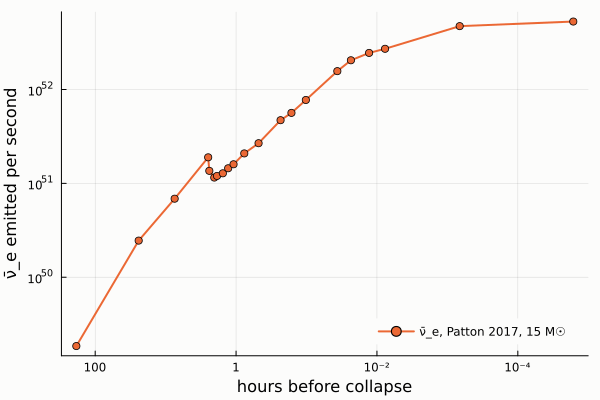

In [14]:
presn = Patton_2017(progenitor_mass = 15)
Ep = range(0.1, 10, length = 100)
tp = times(presn)[2:end-1]   # from 8 days to 60 ms before the collapse
Sp = initial_spectra(presn, tp, Ep)
nν = vec(integrate(Sp[:e_bar], :energy).array)
plot(-tp ./ 3600, nν; xscale = :log10, yscale = :log10, xflip = true, marker = :circle, color = FLAVOR_COLOR[:e_bar], label = "ν̄_e, Patton 2017, 15 M☉", legend = :bottomright,
     xticks = ([1e-4, 1e-2, 1, 100], ["10⁻⁴", "10⁻²", "1", "100"]),
     xlabel = "hours before collapse", ylabel = "ν̄_e emitted per second")

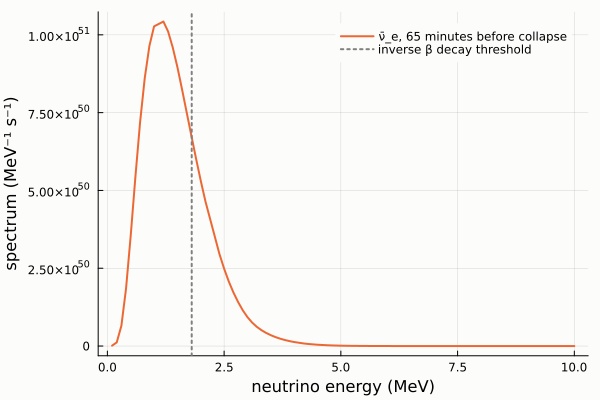

In [15]:
i = argmin(abs.(tp .+ 3600))   # the time step closest to one hour before the collapse
plot(Ep, vec(Sp[:e_bar].array[1, i, :]); label = "ν̄_e, $(round(Int, -tp[i] / 60)) minutes before collapse", color = FLAVOR_COLOR[:e_bar], xlabel = "neutrino energy (MeV)", ylabel = "spectrum (MeV⁻¹ s⁻¹)")
vline!([1.806]; color = :gray, linestyle = :dot, label = "inverse β decay threshold")

Most of the spectrum lies below the 1.8 MeV threshold of inverse β decay. Only its tail is detectable, which is why pre-supernova alerts need large, quiet detectors.

## Your own model

`PinchedModel` and `Analytic3Species` describe a supernova by the luminosity, mean energy and pinching α of each flavor over time. Here is a simple model in a file, with constant luminosities:

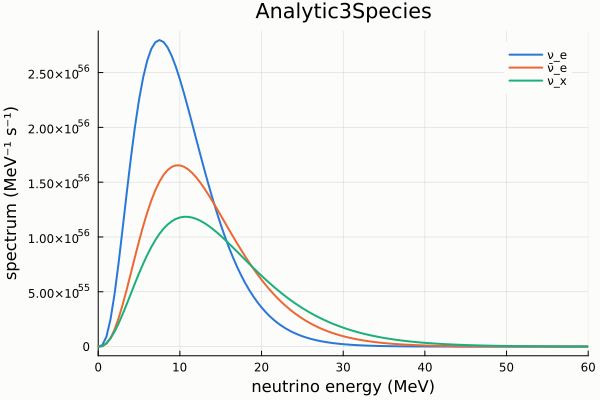

In [16]:
file = joinpath(mktempdir(), "analytic.dat")
write(file, """
TIME L_NU_E L_NU_E_BAR L_NU_X E_NU_E E_NU_E_BAR E_NU_X ALPHA_NU_E ALPHA_NU_E_BAR ALPHA_NU_X
0.0 5e52 5e52 5e52 10 13 15 3 3 2.5
1.0 5e52 5e52 5e52 10 13 15 3 3 2.5
""")
analytic = Analytic3Species(file)
Sa = initial_spectra(analytic, [0.5], E)
plot(; xlabel = "neutrino energy (MeV)", ylabel = "spectrum (MeV⁻¹ s⁻¹)", xlims = (0, 60), title = "Analytic3Species")
for f in (:e, :e_bar, :mu)
    plot!(E, vec(Sa[f].array); label = LABEL[f], color = FLAVOR_COLOR[f])
end
plot!()

## Differences from SNEWPY

The port fixes several bugs of SNEWPY. They are listed in the [README](https://github.com/JuliaNeutrino/SupernovaNeutrinos.jl#differences-from-snewpy). Among them:

- the μ–τ content of the matter eigenstates at high density used the wrong sign in a square root;
- `Bugli_2021` squared ⟨E²⟩ twice, which gave pinch parameters α ≈ −1;
- spectra are zero outside the simulated times instead of holding the first and last values;
- integration is exact for partial bins.

With all that, the event totals for the `Bollig_2016` 11.2 M☉ model agree with SNEWPY's cross-check values to 1%.